# Are taxi rides just a game?
## Analyzing taxi tipping behavior between drivers and passengers in NYC

**Math 30.04 — Evolutionary Game Theory · Spring 2026**  
Charles Nelson · Julia Fausto · Lourdes Lauterborn · Mithun Rameshkumar

---

This notebook contains the full data pipeline and analysis behind the paper. It:

1. Downloads 13 quarterly Yellow Taxi trip files from the NYC TLC public data portal
2. Filters to Manhattan-internal, weekday rush-hour, credit-card-paid, non-airport rides (~6.5M rows)
3. Estimates the model parameters $\tau$ (mean tip) and $m$ (meter-max premium) per quarter
4. Simulates replicator dynamics and produces phase portraits for the strong and weak signaling regimes
5. Plots the empirical tip-rate trajectory and identifies the January 2025 congestion-fee shock

## 1. Setup and dependencies

In [8]:
import os
import requests
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import warnings
warnings.filterwarnings('ignore')

# Configuration
DATA_DIR = './taxi_data'
os.makedirs(DATA_DIR, exist_ok=True)

# Color palette for figures
YELLOW = '#F7BA1E'
BLUE = '#2563EB'
GRAY = '#404040'
BLACK = '#1A1A1A'

plt.rcParams.update({
    'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False
})

## 2. Download NYC TLC trip records

We download Yellow Taxi trip parquet files from the NYC TLC's CloudFront CDN. We sample one month per quarter (February, May, August, November) across 2023–2025, plus February 2026.

In [9]:
BASE_URL = 'https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{year}-{month:02d}.parquet'

# Quarterly sampling: Feb, May, Aug, Nov of 2023, 2024, 2025 + Feb 2026
QUARTERS = [(y, m) for y in (2023, 2024, 2025) for m in (2, 5, 8, 11)] + [(2026, 2)]

for year, month in QUARTERS:
    filename = f'yellow_tripdata_{year}-{month:02d}.parquet'
    filepath = os.path.join(DATA_DIR, filename)
    if os.path.exists(filepath):
        print(f'  Already have: {filename}')
        continue
    url = BASE_URL.format(year=year, month=month)
    print(f'  Downloading: {filename}')
    r = requests.get(url, stream=True, timeout=120)
    r.raise_for_status()
    with open(filepath, 'wb') as f:
        for chunk in r.iter_content(chunk_size=8192):
            f.write(chunk)

print(f'\nAll {len(QUARTERS)} files in {DATA_DIR}')
print(f'Total size: {sum(os.path.getsize(os.path.join(DATA_DIR, f"yellow_tripdata_{y}-{m:02d}.parquet")) for y, m in QUARTERS) / 1e6:.0f} MB')

  Already have: yellow_tripdata_2023-02.parquet
  Already have: yellow_tripdata_2023-05.parquet
  Already have: yellow_tripdata_2023-08.parquet
  Already have: yellow_tripdata_2023-11.parquet
  Already have: yellow_tripdata_2024-02.parquet
  Already have: yellow_tripdata_2024-05.parquet
  Already have: yellow_tripdata_2024-08.parquet
  Already have: yellow_tripdata_2024-11.parquet
  Already have: yellow_tripdata_2025-02.parquet
  Already have: yellow_tripdata_2025-05.parquet
  Already have: yellow_tripdata_2025-08.parquet
  Already have: yellow_tripdata_2025-11.parquet
  Already have: yellow_tripdata_2026-02.parquet

All 13 files in ./taxi_data
Total size: 766 MB


## 3. Filter to the analysis sample

We apply four filters in sequence:

1. **Credit-card payments only** (`payment_type == 1`) — TLC only records tips for credit-card payments
2. **Manhattan-internal** — both pickup and dropoff in one of the 69 Manhattan zones
3. **Weekday rush hour** — Mon–Fri, 7–10am or 4–7pm
4. **No airport flat-rate trips** (`RatecodeID` not in {2, 3}) because flat fares decouple the meter from driver effort

We are also dropping rows with invalid speeds, fares, or passenger counts.

In [10]:
# Manhattan TLC location IDs (zones with Borough='Manhattan' in the taxi zone lookup)
MANHATTAN = {4, 12, 13, 24, 41, 42, 43, 45, 48, 50, 68, 74, 75, 79, 87, 88,
             90, 100, 103, 104, 105, 107, 113, 114, 116, 120, 125, 127, 128,
             137, 140, 141, 142, 143, 144, 148, 151, 152, 153, 158, 161, 162,
             163, 164, 166, 170, 186, 194, 202, 209, 211, 224, 229, 230, 231,
             232, 233, 234, 236, 237, 238, 239, 243, 244, 246, 249, 261, 262, 263}

def filter_quarter(parquet_path):
    cols = ['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count',
            'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID',
            'payment_type', 'fare_amount', 'tip_amount']
    df = pd.read_parquet(parquet_path, columns=cols)
    df['duration_min'] = ((df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime'])
                          .dt.total_seconds() / 60.0)
    df['day_of_week'] = df['tpep_pickup_datetime'].dt.dayofweek
    df['hour'] = df['tpep_pickup_datetime'].dt.hour

    mask = (
        (df['payment_type'] == 1) &
        (df['PULocationID'].isin(MANHATTAN)) &
        (df['DOLocationID'].isin(MANHATTAN)) &
        (~df['RatecodeID'].isin([2, 3])) &
        (df['fare_amount'] > 0) & (df['fare_amount'] < 200) &
        (df['passenger_count'] > 0) &
        (df['trip_distance'] > 0.1) & (df['trip_distance'] < 25) &
        (df['duration_min'] > 0) & (df['duration_min'] < 180) &
        (df['day_of_week'] < 5) &
        ((df['hour'].between(7, 9)) | (df['hour'].between(16, 18)))
    )
    df = df[mask].copy()
    df['mph'] = df['trip_distance'] / (df['duration_min'] / 60.0)
    df = df[(df['mph'] >= 0.5) & (df['mph'] <= 60)]
    return df

# Run filter on all 13 files
filtered_chunks = []
for year, month in QUARTERS:
    period = f'{year}-{month:02d}'
    filepath = os.path.join(DATA_DIR, f'yellow_tripdata_{year}-{month:02d}.parquet')
    chunk = filter_quarter(filepath)
    chunk['period'] = period
    chunk['tip_rate'] = chunk['tip_amount'] / chunk['fare_amount']
    chunk['tipped'] = (chunk['tip_amount'] > 0).astype(int)
    filtered_chunks.append(chunk)
    print(f'  {period}: {len(chunk):>8,} rides')

filtered = pd.concat(filtered_chunks, ignore_index=True)
print(f'\nTotal filtered sample: {len(filtered):,} rides across {len(QUARTERS)} quarters')

  2023-02:  487,837 rides
  2023-05:  581,690 rides
  2023-08:  448,904 rides
  2023-11:  549,363 rides
  2024-02:  509,560 rides
  2024-05:  579,744 rides
  2024-08:  438,992 rides
  2024-11:  539,183 rides
  2025-02:  508,626 rides
  2025-05:  571,925 rides
  2025-08:  407,837 rides
  2025-11:  497,991 rides
  2026-02:  423,999 rides

Total filtered sample: 6,545,651 rides across 13 quarters


## 4. Estimate model parameters τ and m per quarter

**τ (tau)** — the mean tip on tipped credit-card trips. Straightforward: TLC records tip amounts directly.

**m (meter-max premium)** is estimated via a fare-baseline method:

1. Within each quarter, bin trips by distance (20 equal-width bins)
2. Within each distance bin, the fastest 25% of trips by pace serve as the efficient-fare baseline (their median fare)
3. For every trip, compute excess fare = actual − baseline (for its bin)
4. m = mean excess on trips with excess > $0.50 (the noise threshold)

In [11]:
def estimate_quarter_params(g):
    tipped = g[g['tipped'] == 1]
    tau = float(tipped['tip_amount'].mean())

    # m: fast-quartile fare baseline
    fast = g[g['mph'] >= g['mph'].quantile(0.75)]
    bins = np.linspace(g['trip_distance'].min(), g['trip_distance'].max(), 21)
    fast_bin = np.clip(np.digitize(fast['trip_distance'], bins) - 1, 0, 19)
    expected_by_bin = fast.groupby(fast_bin)['fare_amount'].median()
    trip_bin = np.clip(np.digitize(g['trip_distance'], bins) - 1, 0, 19)
    expected_fare = pd.Series(trip_bin).map(expected_by_bin).ffill().bfill().values
    excess = g['fare_amount'].values - expected_fare
    pos = excess[excess > 0.5]
    m = float(pos.mean()) if len(pos) > 100 else 0.0

    return {
        'period': g['period'].iloc[0],
        'n_rides': len(g),
        'tau': round(tau, 3),
        'm': round(m, 3),
        'tip_rate_pct': round(g['tip_rate'].mean() * 100, 2),
        'tip_incidence_pct': round(g['tipped'].mean() * 100, 2),
    }

params = pd.DataFrame([estimate_quarter_params(g) for _, g in filtered.groupby('period')])
params = params.sort_values('period').reset_index(drop=True)
params

,period,n_rides,tau,m,tip_rate_pct,tip_incidence_pct
0,2023-02,487837,3.386,3.270,26.78,97.16
1,2023-05,581690,3.554,4.040,26.29,97.14
2,2023-08,448904,3.455,3.509,26.66,96.47
3,2023-11,549363,3.586,4.235,26.54,97.18
4,2024-02,509560,3.422,3.540,26.94,97.01
5,2024-05,579744,3.583,4.170,26.56,96.75
6,2024-08,438992,3.470,3.800,26.67,95.66
7,2024-11,539183,3.543,4.199,26.44,96.47
8,2025-02,508626,3.447,3.395,27.71,96.33
9,2025-05,571925,3.639,4.229,27.02,96.09


### Headline numerical findings

In [12]:
print(f'τ (mean tip):         ${params["tau"].mean():.2f}  (range ${params["tau"].min():.2f}–${params["tau"].max():.2f})')
print(f'm (meter-max premium): ${params["m"].mean():.2f}  (range ${params["m"].min():.2f}–${params["m"].max():.2f})')
print(f'Tip incidence:         {params["tip_incidence_pct"].mean():.1f}%  (range {params["tip_incidence_pct"].min():.1f}–{params["tip_incidence_pct"].max():.1f}%)')
print(f'\nm > τ in {(params["m"] > params["tau"]).sum()} of {len(params)} quarters → cooperative outcome (1,1) cannot be sustained by reciprocity')
print(f'Tip incidence near 95% → NYC sits in the strong-signaling regime (0,1)')

τ (mean tip):         $3.53  (range $3.39–$3.67)
m (meter-max premium): $3.89  (range $3.27–$4.47)
Tip incidence:         96.3%  (range 95.0–97.2%)

m > τ in 11 of 13 quarters → cooperative outcome (1,1) cannot be sustained by reciprocity
Tip incidence near 95% → NYC sits in the strong-signaling regime (0,1)


## 5. Replicator dynamics and phase portraits

The two-population game has driver fitness difference $\Delta f_{\text{driver}} = -m$ (a constant — meter-maxing always dominates) and passenger fitness difference

$$\Delta f_{\text{passenger}} = x \cdot s_0 + (\alpha + \beta)\ln(n) - \tau.$$

Setting this to zero gives the passenger indifference threshold $x^* = (\tau - (\alpha+\beta)\ln n) / s_0$. The sign of $x^*$ separates two regimes:

- **Strong signaling**: $(\alpha+\beta)\ln(n) > \tau$ → $x^* < 0$ → tipping pays for all $x$ → trajectories converge to $(0, 1)$
- **Weak signaling**: $(\alpha+\beta)\ln(n) < \tau$ → $x^* \in (0, 1)$ → cascade collapse to $(0, 0)$

In [13]:
def phase_portrait(ax, m_val, tau, ab, s0, n, title, attractor=None):
    '''Draw replicator-dynamics phase portrait on [0,1]^2.'''
    X, Y = np.meshgrid(np.linspace(0.02, 0.98, 22), np.linspace(0.02, 0.98, 22))
    df_pass = X * s0 + ab * np.log(n) - tau
    DX = X * (1 - X) * (-m_val)
    DY = Y * (1 - Y) * df_pass
    mag = np.sqrt(DX**2 + DY**2) + 1e-12
    ax.quiver(X, Y, DX / mag, DY / mag, mag, cmap='Greys',
              alpha=0.65, scale=30, width=0.0035)

    # Indifference threshold x*, if it falls in (0, 1)
    x_star = (tau - ab * np.log(n)) / s0
    if 0 < x_star < 1:
        ax.axvline(x_star, color=YELLOW, ls='--', lw=2.5,
                   label=f'x* = {x_star:.2f}')

    # Trajectories from a handful of starting points
    def odes(state, t):
        x, y = state
        return [x*(1-x)*(-m_val), y*(1-y)*(x*s0 + ab*np.log(n) - tau)]
    for s in [(0.9, 0.9), (0.9, 0.4), (0.6, 0.9), (0.3, 0.7),
              (0.7, 0.2), (0.2, 0.3), (0.5, 0.5), (0.15, 0.85)]:
        traj = odeint(odes, s, np.linspace(0, 200, 1000))
        ax.plot(traj[:, 0], traj[:, 1], color=BLUE, lw=1.8, alpha=0.75)
        ax.scatter(*s, color=BLUE, s=22, zorder=5,
                   edgecolor='white', lw=0.8)

    if attractor is not None:
        ax.scatter(*attractor, marker='*', s=520, color=YELLOW, zorder=10,
                   edgecolor=BLACK, lw=1.5,
                   label=f'ESS = ({attractor[0]}, {attractor[1]})')

    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('x — share of Tip-Max drivers')
    ax.set_ylabel('y — share of Tippers')
    ax.set_title(title, fontweight='bold')
    ax.set_aspect('equal')
    ax.legend(loc='upper right', framealpha=0.95, fontsize=10)
    ax.grid(True, alpha=0.2)

### Figure 1 — Strong signaling regime

Parameters chosen so $(\alpha+\beta)\ln(n) > \tau$. Tipping pays at every $x$, even when no drivers are efficient. Trajectories converge to $(0, 1)$.

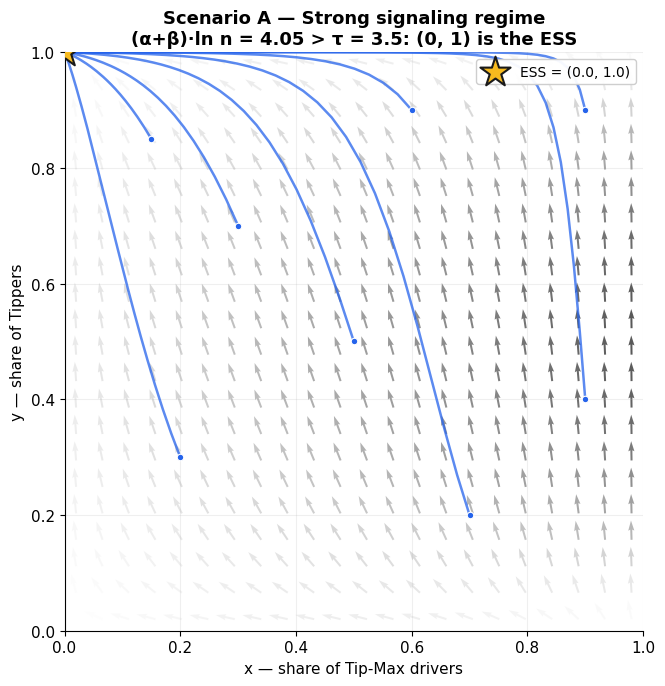

In [14]:
fig, ax = plt.subplots(figsize=(7, 7), facecolor='white')
phase_portrait(ax, m_val=0.5, tau=3.5, ab=10, s0=2.0, n=1.5,
               title='Scenario A — Strong signaling regime\n(α+β)·ln n = 4.05 > τ = 3.5: (0, 1) is the ESS',
               attractor=(0.0, 1.0))
plt.tight_layout()
plt.savefig('fig_strong_signaling.png', dpi=160, bbox_inches='tight')
plt.show()

### Figure 2 — Weak signaling regime

Parameters chosen so $(\alpha+\beta)\ln(n) < \tau$. The threshold $x^* \approx 0.49$ is now visible inside the unit square. Driver dynamics pull $x$ leftward across the threshold, and once it crosses, the passenger best-response flips and $y$ collapses. All trajectories converge to $(0, 0)$.

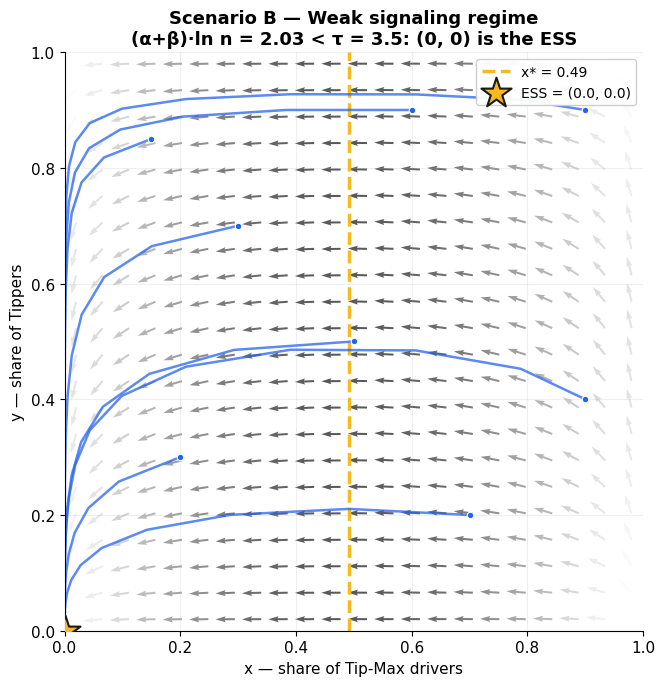

In [15]:
fig, ax = plt.subplots(figsize=(7, 7), facecolor='white')
phase_portrait(ax, m_val=4.4, tau=3.5, ab=5, s0=3.0, n=1.5,
               title='Scenario B — Weak signaling regime\n(α+β)·ln n = 2.03 < τ = 3.5: (0, 0) is the ESS',
               attractor=(0.0, 0.0))
plt.tight_layout()
plt.savefig('fig_weak_signaling.png', dpi=160, bbox_inches='tight')
plt.show()

## 6. Empirical tip-rate trajectory and the January 2025 congestion fee

Now we plot how the observed mean credit-card tip rate evolved across the 13 quarters. The vertical dashed line marks January 5, 2025, which is the day NYC instituted a flat $1.50 congestion fee on trips entering the central business district. The fee replaced what was previously discretionary fare-padding, so the meter-max premium $m$ should compress at that point.

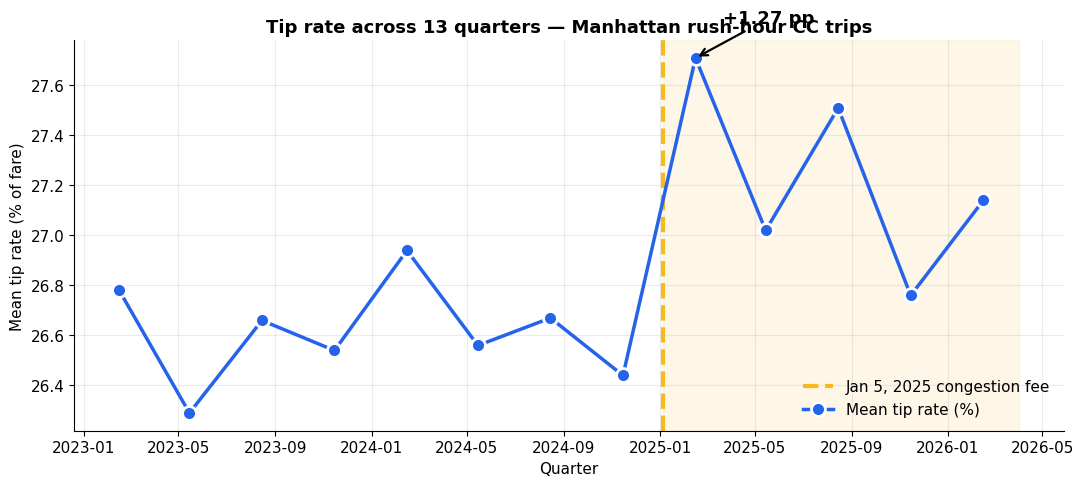

In [16]:
params['period_dt'] = pd.to_datetime(params['period'] + '-15')
params = params.sort_values('period_dt').reset_index(drop=True)
shock = pd.Timestamp('2025-01-05')

fig, ax = plt.subplots(figsize=(11, 5), facecolor='white')
ax.axvspan(shock, params['period_dt'].max() + pd.Timedelta(days=45),
           alpha=0.10, color=YELLOW)
ax.axvline(shock, color=YELLOW, lw=3, ls='--',
           label='Jan 5, 2025 congestion fee')
ax.plot(params['period_dt'], params['tip_rate_pct'],
        marker='o', color=BLUE, lw=2.5, ms=10,
        markerfacecolor=BLUE, markeredgecolor='white',
        markeredgewidth=2, label='Mean tip rate (%)')

# Annotate the jump
pre = params[params['period'] == '2024-11'].iloc[0]
post = params[params['period'] == '2025-02'].iloc[0]
ax.annotate(f'+{post.tip_rate_pct - pre.tip_rate_pct:.2f} pp',
            xy=(post.period_dt, post.tip_rate_pct),
            xytext=(20, 25), textcoords='offset points',
            fontsize=13, fontweight='bold',
            arrowprops=dict(arrowstyle='->', lw=1.6))

ax.set_xlabel('Quarter')
ax.set_ylabel('Mean tip rate (% of fare)')
ax.set_title('Tip rate across 13 quarters — Manhattan rush-hour CC trips',
             fontweight='bold')
ax.legend(loc='lower right', frameon=False)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig('fig_empirical_trajectory.png', dpi=160, bbox_inches='tight')
plt.show()

## 7. Summary of empirical results

1. **$m > \tau$ in every quarter.** 

2. **Tip incidence holds at ~95% throughout.**

The January 5, 2025 congestion fee provides supporting evidence.


In [18]:
# Final summary table
summary = params[['period', 'n_rides', 'tau', 'm', 'tip_rate_pct', 'tip_incidence_pct']].copy()
summary.columns = ['Quarter', 'Rides', 'τ ($)', 'm ($)', 'Tip rate (%)', 'Tip incidence (%)']
summary

,Quarter,Rides,τ ($),m ($),Tip rate (%),Tip incidence (%)
0,2023-02,487837,3.386,3.270,26.78,97.16
1,2023-05,581690,3.554,4.040,26.29,97.14
2,2023-08,448904,3.455,3.509,26.66,96.47
3,2023-11,549363,3.586,4.235,26.54,97.18
4,2024-02,509560,3.422,3.540,26.94,97.01
5,2024-05,579744,3.583,4.170,26.56,96.75
6,2024-08,438992,3.470,3.800,26.67,95.66
7,2024-11,539183,3.543,4.199,26.44,96.47
8,2025-02,508626,3.447,3.395,27.71,96.33
9,2025-05,571925,3.639,4.229,27.02,96.09
